<a href="https://colab.research.google.com/github/dileepsgdileep/ai.1/blob/main/SVM%2CRBF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (569, 30)
Target shape: (569,)
Features names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Class names:
['malignant' 'benign']
Input shape: (569, 30)
Output shape: (569,)
Training data: (455, 30)
Testing data: (114, 30)
Training shape: (455, 30)
Testing shape: (114, 30)
Predict values:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 

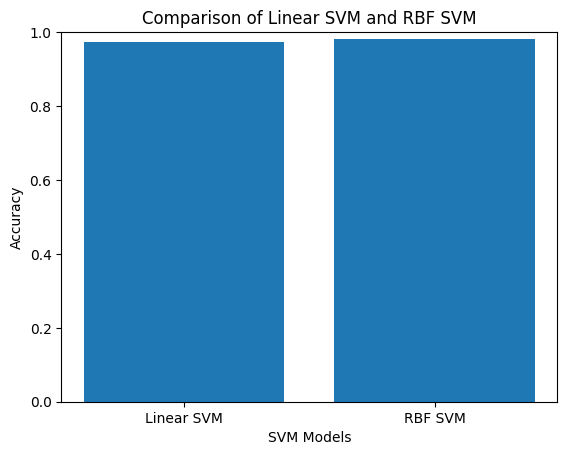

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data=load_breast_cancer()
x=data.data
y=data.target
print("Dataset shape:",x.shape)
print("Target shape:",y.shape)
print("Features names:")
print(data.feature_names)
print("Class names:")
print(data.target_names)

df=pd.DataFrame(x,columns=data.feature_names)
df['Target']=y
df.head()

X=df.drop('Target',axis=1)
y=df['Target']
print("Input shape:",X.shape)
print("Output shape:",y.shape)


X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Training shape:",X_train_scaled.shape)
print("Testing shape:",X_test_scaled.shape)

linear_svm=SVC(kernel='linear',C=1.0)
linear_svm.fit(X_train_scaled,y_train)

y_pred_linear=linear_svm.predict(X_test_scaled)
print("Predict values:")
print(y_pred_linear)
print("Actual values:")
print(y_test.values)

accuracy_linear=accuracy_score(y_test,y_pred_linear)
print("Linear SVM Accuracy:",accuracy_linear)

cm_linear=confusion_matrix(y_test,y_pred_linear)
print("Confusion Matrix:")
print(cm_linear)

print(classification_report(
    y_test,
    y_pred_linear,
    target_names=data.target_names
    ))
rbf_svm=SVC(kernel='rbf',C=1.0,gamma='scale')
rbf_svm.fit(X_train_scaled,y_train)

y_pred_rbf=rbf_svm.predict(X_test_scaled)
print("Predict values:")
print(y_pred_rbf)
print("Actual values:")
print(y_test.values)

accuracy_rbf=accuracy_score(y_test,y_pred_rbf)
print("RBF SVM Accuracy:",accuracy_rbf)

cm_rbf=confusion_matrix(y_test,y_pred_rbf)
print("Confusion Matrix:")
print(cm_rbf)

print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=data.target_names
))

print("Linear SVM Accuracy:",accuracy_linear)
print("RBF SVM Accuracy:",accuracy_rbf)
if accuracy_linear>accuracy_rbf:
  print("Linear SVM performs better")
elif accuracy_rbf>accuracy_linear:
  print("RBF SVM performs better")
else:
  print("Both models have equal accuracy.")


models=['Linear SVM','RBF SVM']
accuracy=[accuracy_linear,accuracy_rbf]
plt.bar(models,accuracy)
plt.xlabel('SVM Models')
plt.ylabel('Accuracy')
plt.title('Comparison of Linear SVM and RBF SVM')
plt.ylim(0,1)
plt.show()
